# Random and Local Search (Part 1)

## Random Search

Before we can code, some imports: We are considering randomised algorithms, and we want to plot results. To run this notebook, you will also need matplotlib, numpy, and scipy installed.

In [1]:
import matplotlib.pyplot as plt
import random
from sbse_support import seed_everything
seed_everything()
import math

We will start with the One-Max problem: The aim of this optimisation problem is to find a binary vector of length `n` such that all elements are `1`. The solution is obvious to us, but not to a search algorithm. We first need to decide on a specific length of `n` for our experiments.

In [2]:
n = 20

In order to do any kind of random search, we need to be able to randomly sample solutions from the search space.

In [3]:
def get_random_solution():
    return [random.choice([0,1]) for _ in range(n)]

Now we can look at an example solution from our search space:

In [4]:
get_random_solution()

[0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1]

Every invocation will produce a different individual

In [5]:
get_random_solution()

[0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0]

To solve an optimisation problem, we also need an objective function, or _fitness function_, that quantifies how good a particular solution is with respect to the optimisation problem we are trying to solve. For our example one max problem, we can estimate how close we are to solving the problem by counting the number of `1`s in our solution.

In [6]:
def get_fitness(solution):
    return sum(solution)

In [7]:
get_fitness([0,0,0,0,0])

0

In [8]:
get_fitness([1,1,1,0,0])

3

Each search returns its best solution and a _history_: the best fitness seen so far after each fitness evaluation, starting with the first candidate. Plotting the history shows how quickly a search improves.

In [9]:
def plot_history(history, label=None):
    plt.plot(history, label=label)
    plt.xlabel("Fitness evaluations")
    plt.ylabel("Best fitness so far")

In some cases, we know when we have found an optimal solution; sometimes we don't. Sometimes it may also take very long to find the optimal solution, therefore we limit the search with some _stopping criterion_. We will start by running the search for a fixed number of steps.

In [10]:
max_steps = 100

The following implements our first metaheuristic: _Random Search_. It's not a particularly intelligent one, but it will be the baseline we are going to compare against from now on. If the fitness landscape is bad, this algorithm may actually be better than many other metaheuristics.

In [11]:
def randomsearch():
    best = get_random_solution()
    best_fitness = get_fitness(best)
    history = [best_fitness]
    while len(history) < max_steps:
        candidate = get_random_solution()
        fitness = get_fitness(candidate)
        if fitness > best_fitness:
            best, best_fitness = candidate, fitness
        history.append(best_fitness)
    return best, history

Invoking it gives us back both the best solution and the history of the search:

In [12]:
solution, history = randomsearch()

We kept track of the best solution found throughout the search, and we will use this information to learn about the progress, and compare search algorithms. Therefore, we are going to visualise it.

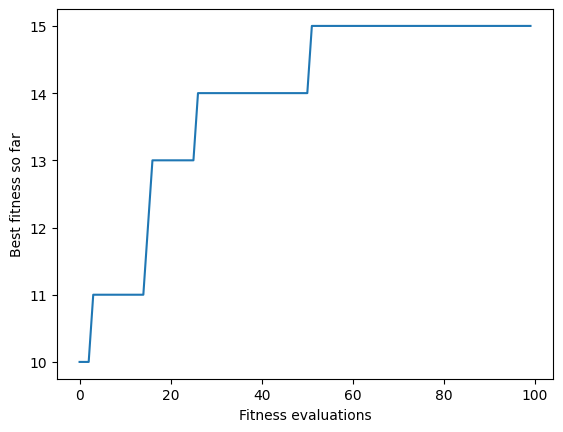

In [13]:
plot_history(history)

If you re-run the search multiple times you will get different results, but even for small values of `n` the random search will rarely find an optimal solution.

Random search is a _global_ search algorithm -- it considers the entire search space. An alternative strategy is to consider the local neighbourhood of candidate solutions, resulting in _local_ search algorithms. As a naive baseline, we can change our random search to a local random search, also known as a _random walk_. A random walk consists of repeatedly picking a random neighbour for a given candidate solution, therefore we need to define a function that picks a random neighbour; that is, a solution which differs only in a single step (in our case, a bit-flip).

In [14]:
def get_neighbour(candidate):
    pos = random.randint(0, len(candidate) - 1)
    copy = candidate[:]
    copy[pos] = 1 - copy[pos]
    return copy

In [15]:
get_neighbour([0,0,0,0,0,1,0,0,0,0])

[0, 0, 0, 1, 0, 1, 0, 0, 0, 0]

In [16]:
get_neighbour([0,0,0,0,0,1,0,0,0,0])

[0, 0, 0, 0, 0, 1, 0, 0, 1, 0]

In [17]:
get_neighbour([0,0,0,0,0,1,0,0,0,0])

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

To do a random walk, we start at a random solution, and repeatedly pick a random neighbour. Along the search, we keep track of the best solution found.

Every algorithm needs the same bookkeeping as random search: count fitness evaluations, remember the best solution, and record the history. The small `Evaluations` helper from `sbse_support` does this for us. Calling `evaluate(candidate)` returns the fitness and updates the best solution and history; `evaluate.remaining` is the number of evaluations left in the budget, and `evaluate.result()` returns the best solution and the history. Every call counts, including repeated candidates: we are counting fitness evaluations, not unique solutions.

In [18]:
from sbse_support import Evaluations

def randomwalk():
    evaluate = Evaluations(get_fitness, max_steps)
    current = get_random_solution()
    evaluate(current)
    while evaluate.remaining:
        current = get_neighbour(current)
        evaluate(current)
    return evaluate.result()

In [19]:
solution, history = randomwalk()

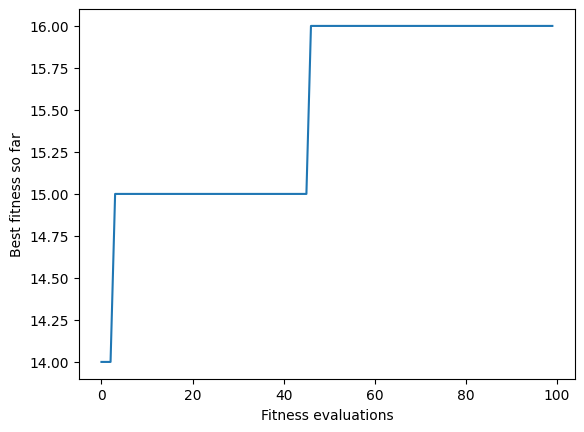

In [20]:
plot_history(history)

A random walk usually isn't well suited as an actual search algorithm; it tends to produce even worse solutions than random search (at least on one max). However, we can now generalise the idea of exploring the neighbourhood to construct some actual local search algorithms.

## Local Search

A local search algorithm consists of (1) a definition of the neighbourhood for a candidate solution, and (2) an exploration operator that picks the next step in the neighbourhood. The neighbourhood is the set of solutions that one can reach from a candidate solution in one step -- in our case, with a single bit flip:

In [21]:
def get_neighbours(candidate):
    neighbours = []
    for pos in range(len(candidate)):
        copy = candidate[:]
        copy[pos] = 1 - copy[pos]
        neighbours.append(copy)
    return neighbours

bit_neighbours = get_neighbours  # retain this neighbourhood when the problem changes

In [22]:
get_neighbours([0,0,0,0,0,1,0,0,0,0])

[[1, 0, 0, 0, 0, 1, 0, 0, 0, 0],
 [0, 1, 0, 0, 0, 1, 0, 0, 0, 0],
 [0, 0, 1, 0, 0, 1, 0, 0, 0, 0],
 [0, 0, 0, 1, 0, 1, 0, 0, 0, 0],
 [0, 0, 0, 0, 1, 1, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 1, 1, 0, 0, 0],
 [0, 0, 0, 0, 0, 1, 0, 1, 0, 0],
 [0, 0, 0, 0, 0, 1, 0, 0, 1, 0],
 [0, 0, 0, 0, 0, 1, 0, 0, 0, 1]]

### Hillclimbing

The first local search algorithm we consider is very simple: The exploration operator always picks the best neighbour. The result is called _hillclimbing_ because it climbs a hill in the fitness landscape (if we assume a maximisation problem, like in the case of one max). Starting from a random individual, we consider all neighbours, and pick the best one. Then, we repeat this process for this neighbour. The new point in the search space has to be strictly better.

In [23]:
def hillclimbing(start=None, fitness=None, neighbours=None, budget=None):
    evaluate = Evaluations(fitness or get_fitness, max_steps if budget is None else budget)
    neighbours = neighbours or get_neighbours
    current = get_random_solution() if start is None else list(start)
    score = evaluate(current)
    while evaluate.remaining:
        candidate, candidate_score = current, score
        for neighbour in neighbours(current):
            if not evaluate.remaining:
                break
            value = evaluate(neighbour)
            if value > candidate_score:
                candidate, candidate_score = neighbour, value
        if candidate_score <= score:
            break
        current, score = candidate, candidate_score
    return evaluate.result()

Calling `hillclimbing()` uses the current problem definitions and evaluation cap, just like random search. Optional arguments let us supply a starting solution, fitness function, neighbourhood or budget without redefining the algorithm; the appendix uses this for NK landscapes.

In [24]:
solution, history = hillclimbing()

On One Max, every zero bit offers an improving move. With enough evaluations, hillclimbing reaches the optimum in at most `n` improving moves. Each full scan costs `n` evaluations, however, so `n` moves are not `n` evaluations: a smaller budget can stop the search before it reaches the optimum.

A hillclimber also stops early once no neighbour is better, so its history can be shorter than the budget. Always compare histories on their actual evaluation axis.

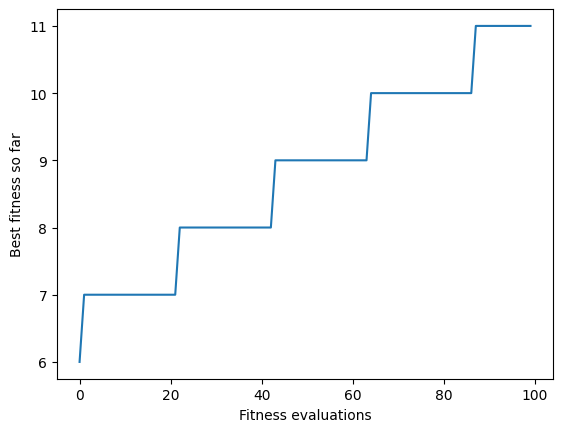

In [25]:
plot_history(history)

## Compiler Flag Selection

So far we have optimised a toy fitness function. Choosing compiler flags gives us a software configuration problem: represent enabled flags as bits and minimise the compiled program's size.

The supplied table contains all $2^8 = 256$ combinations of eight flags for one small C program (`data/flags/program.c`). The accompanying script (`data/flags/measure.py`) documents the intended measurement procedure: compile at `-O2` with explicit `-fX`/`-fno-X` settings and record unpadded section bytes within `__TEXT`. Looking up a configuration in `data/flags/sizes.csv` lets us demonstrate search without compiling during class.

These are configuration choices, not guarantees of equivalent behaviour. In particular, flags such as `wrapv` concern language semantics; an engineering study needs an explicit input domain and behavioural checks. The CSV does not record compiler version, machine details or test results. Also, `/usr/bin/gcc` on macOS may invoke Apple Clang. Treat the table as a frozen teaching instance rather than a general claim about GCC or compiler optimisation.

We can inspect the whole instance here. For dozens of options, exhaustive measurement becomes impractical; search then becomes a way to choose which configurations to evaluate.

In [26]:
import csv

sizes = {}
with open("data/flags/sizes.csv") as f:
    for row in csv.DictReader(f):
        config = tuple(int(row[f"flag{i + 1}"]) for i in range(8))
        sizes[config] = int(row["size"])

len(sizes), min(sizes.values()), max(sizes.values())

(256, 1902, 7218)

The sizes of all 256 configurations show that the choice of flags makes a large difference:

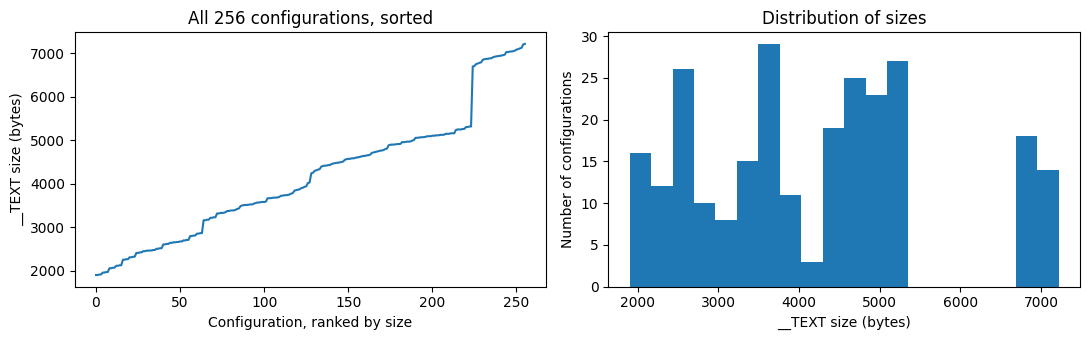

In [27]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))
ax1.plot(sorted(sizes.values()))
ax1.set(xlabel="Configuration, ranked by size", ylabel="__TEXT size (bytes)",
        title="All 256 configurations, sorted")
ax2.hist(sizes.values(), bins=20)
ax2.set(xlabel="__TEXT size (bytes)", ylabel="Number of configurations",
        title="Distribution of sizes")
plt.tight_layout()

The representation and single-bit neighbourhood are the same as for One Max, so we can reuse both search algorithms. They maximise fitness; we score a configuration by the bytes it saves relative to the largest program in the table. Negating size would also work: `Evaluations` supports negative fitness.

In [28]:
worst_size = max(sizes.values())

def get_fitness(config):
    return worst_size - sizes[tuple(config)]

def get_random_solution():
    return [random.choice([0, 1]) for _ in range(8)]

Let's see how our two algorithms cope with this space. It only has 256 points, so we can afford a small budget.

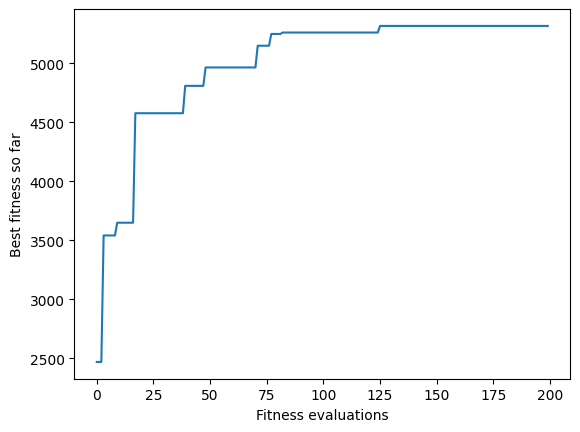

In [29]:
max_steps = 200
solution, history = randomsearch()
plot_history(history)

Now the hillclimber, which looks at all 8 neighbours before deciding where to step:

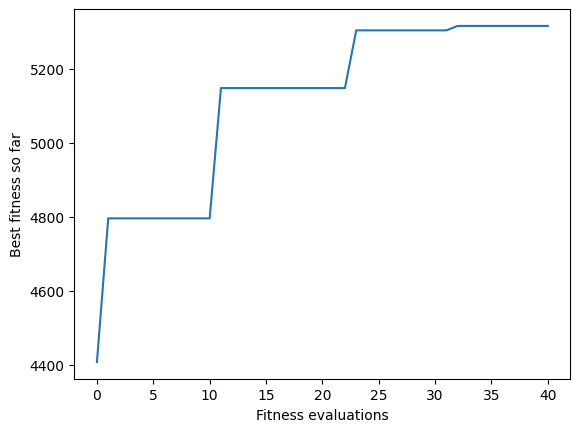

In [30]:
solution, history = hillclimbing()
plot_history(history)

A single run can make the algorithms look almost identical. Compare repeated runs at several evaluation caps, recording both distance from the best measured size and how often the exact optimum is found. Hillclimbing can terminate before its cap; random search uses it all.

In [31]:
import numpy as np

caps = [16, 32, 64, 200]
runs = 100
best_fitness = worst_size - min(sizes.values())
comparison = {}
for search in [randomsearch, hillclimbing]:
    gaps, successes = [], []
    for max_steps in caps:
        scores = []
        for seed in range(runs):
            random.seed(seed)  # same starting draw for each algorithm
            _, history = search()
            scores.append(history[-1])
        gaps.append(best_fitness - np.mean(scores))
        successes.append(sum(score == best_fitness for score in scores) / runs)
    comparison[search.__name__] = gaps, successes
    print(f"{search.__name__}, cap {caps[-1]}: mean excess {gaps[-1]:.1f} bytes; "
          f"optimum found {successes[-1]:.0%}")
max_steps = 200


randomsearch, cap 200: mean excess 5.9 bytes; optimum found 80%
hillclimbing, cap 200: mean excess 0.0 bytes; optimum found 100%


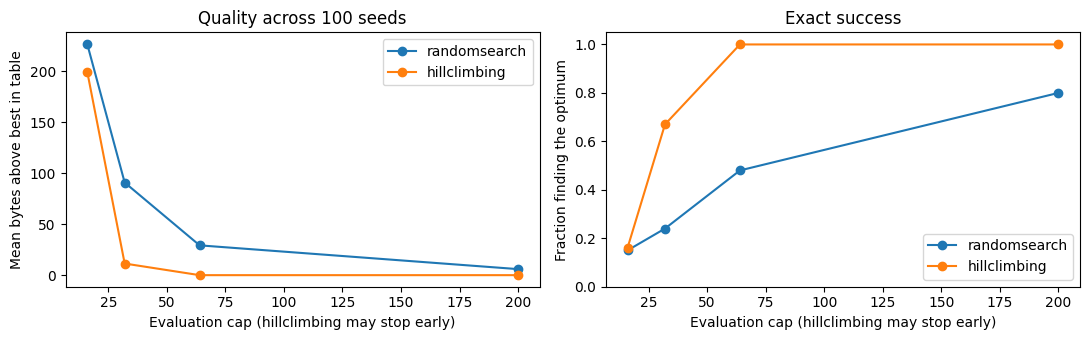

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for label, (gaps, successes) in comparison.items():
    axes[0].plot(caps, gaps, marker="o", label=label)
    axes[1].plot(caps, successes, marker="o", label=label)
for ax in axes:
    ax.set_xlabel("Evaluation cap (hillclimbing may stop early)")
    ax.legend()
axes[0].set(ylabel="Mean bytes above best in table", title=f"Quality across {runs} seeds")
axes[1].set(ylabel="Fraction finding the optimum", ylim=(0, 1.05), title="Exact success")
plt.tight_layout()

At the larger caps, both methods usually produce small programs, so the absolute quality difference is modest. Finding the exact optimum is a separate criterion: random search can get close without finding either of the two optimal configurations. Sampling with replacement at a cap of 200 gives it an exact-success probability of $1-(254/256)^{200} \approx 79\%$.

Hillclimbing uses improving neighbours to reach good configurations with fewer evaluations on this particular table. That is a property of this table, not a general advantage for compiler-flag search: as the next problem shows, a hillclimber can also get stuck.

### The n-queens problem

On one max, every non-optimal solution has an improving neighbour (flip any zero), so hillclimbing cannot get stuck there; it only needs enough budget. However, not all problems are this easy. Let's consider an alternative problem: In the _n-queens_ problem the aim is to place _n_ queens on an _n_ x _n_ chessboard in
such a way that they do not check each other.

As first step, we need to find a way to encode this problem such that we can apply the search on this encoding. A simple representation is a list of length _n_, where each element of the list is an integer up to _n_. That is, each element of the list maps to a column of the chess board, and the value of the element denotes the row in which a queen is located in this column.

In [33]:
def get_random_solution():
    return [random.randint(0, n - 1) for _ in range(n)]

In [34]:
get_random_solution()

[8, 12, 16, 17, 2, 19, 15, 6, 13, 19, 18, 6, 11, 12, 6, 4, 14, 5, 18, 10]

In order to help us interpret such a vector, we can use a simple helper function that visualises the list as a matrix.

In [35]:
def print_solution(solution):
    n = len(solution)
    for y in range(n):
        for x in range(n):
            if solution[x] == y:
                print(" Q ", end = '')
            else:
                print(" . ", end = '')
        print()

In [36]:
n = 8
x = get_random_solution()
print(x)
print_solution(x)

[1, 1, 7, 5, 6, 0, 4, 0]
 .  .  .  .  .  Q  .  Q 
 Q  Q  .  .  .  .  .  . 
 .  .  .  .  .  .  .  . 
 .  .  .  .  .  .  .  . 
 .  .  .  .  .  .  Q  . 
 .  .  .  Q  .  .  .  . 
 .  .  .  .  Q  .  .  . 
 .  .  Q  .  .  .  .  . 


Two queens check each other if they are in the same column, same row, or same diagonal. Since the goal is that no queens check each other, we can formulate an objective function based on how many queens check each other. To be consistent with our previous example, we will make this a _maximisation_ problem, such that the objective function calculates how many queens _don't_ check each other. Using our vector-encoding, there can only be one queen per column by construction. This is a general design choice worth noticing: a representation can make some constraints impossible to violate, so every candidate is _feasible_ with respect to them and the search never wastes evaluations on such violations. The remaining constraints are handled by the objective instead. We thus only need to check if queens are in the same row or diagonal. For each pair of queens that does not check each other, we increase our fitness value by 1:

In [37]:
def get_fitness(solution):
    fitness = 0
    for i in range(len(solution) - 1):
        for j in range(i + 1, len(solution)):
            if solution[i] != solution[j] \
                and solution[i] != solution[j] + (j - i) \
                and solution[j] != solution[i] + (j - i):
                fitness += 1

    return fitness

Here's a simple example of all queens in a row, such that they all check each other -- the fitness is thus 0.

In [38]:
x = [0,0,0,0,0,0,0,0]
print_solution(x)
get_fitness(x)

 Q  Q  Q  Q  Q  Q  Q  Q 
 .  .  .  .  .  .  .  . 
 .  .  .  .  .  .  .  . 
 .  .  .  .  .  .  .  . 
 .  .  .  .  .  .  .  . 
 .  .  .  .  .  .  .  . 
 .  .  .  .  .  .  .  . 
 .  .  .  .  .  .  .  . 


0

Here is a solution where no queens check each other:

In [39]:
x = [4, 0, 3, 5, 7, 1, 6, 2]
print_solution(x)
get_fitness(x)

 .  Q  .  .  .  .  .  . 
 .  .  .  .  .  Q  .  . 
 .  .  .  .  .  .  .  Q 
 .  .  Q  .  .  .  .  . 
 Q  .  .  .  .  .  .  . 
 .  .  .  Q  .  .  .  . 
 .  .  .  .  .  .  Q  . 
 .  .  .  .  Q  .  .  . 


28

The optimal fitness value is n*(n-1)/2 = 28 for n = 8.

Before we can apply search on this problem, we need to define the neighbourhood of our problem. In the simplest case, a neighbour moves a queen up or down by one, taking into account the boundaries of the chess board.

In [40]:
def get_neighbours(solution):
    neighbours = []
    for i in range(len(solution)):
        if solution[i] > 0:
            copy = solution[:]
            copy[i] = copy[i] - 1
            neighbours.append(copy)
        if solution[i] < n - 1:
            copy = solution[:]
            copy[i] = copy[i] + 1
            neighbours.append(copy)

    return neighbours

In [41]:
get_neighbours([4,4,4,4,4,4,4,4])

[[3, 4, 4, 4, 4, 4, 4, 4],
 [5, 4, 4, 4, 4, 4, 4, 4],
 [4, 3, 4, 4, 4, 4, 4, 4],
 [4, 5, 4, 4, 4, 4, 4, 4],
 [4, 4, 3, 4, 4, 4, 4, 4],
 [4, 4, 5, 4, 4, 4, 4, 4],
 [4, 4, 4, 3, 4, 4, 4, 4],
 [4, 4, 4, 5, 4, 4, 4, 4],
 [4, 4, 4, 4, 3, 4, 4, 4],
 [4, 4, 4, 4, 5, 4, 4, 4],
 [4, 4, 4, 4, 4, 3, 4, 4],
 [4, 4, 4, 4, 4, 5, 4, 4],
 [4, 4, 4, 4, 4, 4, 3, 4],
 [4, 4, 4, 4, 4, 4, 5, 4],
 [4, 4, 4, 4, 4, 4, 4, 3],
 [4, 4, 4, 4, 4, 4, 4, 5]]

Let's first try how well random search copes with this problem. Since the problem is quite a bit more difficult than one max, let's also increase the maximum number of steps.

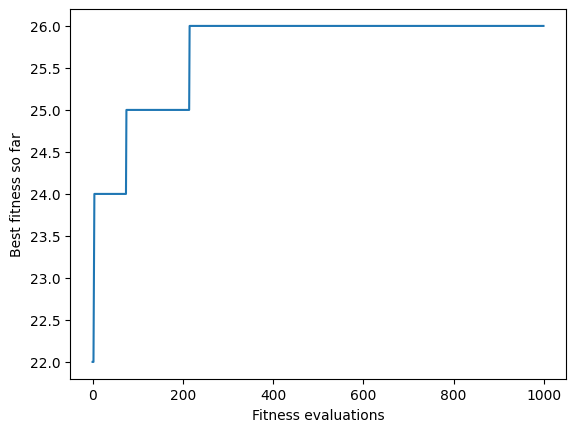

In [42]:
max_steps = 1000
solution, history = randomsearch()
plot_history(history)

Now let's compare this to our local search algorithm, hillclimbing:

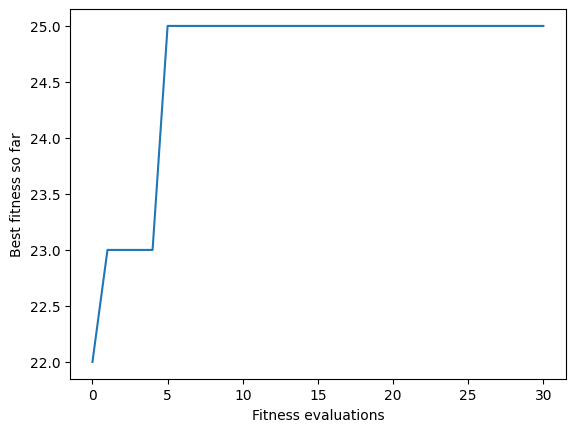

In [43]:
solution, history = hillclimbing()
plot_history(history)

Is hillclimbing still better than random search? A single run of each cannot settle that, but look at the horizontal axis: the hillclimber stops after a few dozen evaluations, long before the budget is spent, while random search keeps sampling. The reason is that, unlike for one max, there are _local optima_ in the search space. Our hillclimber is forced to consider only strictly better neighbours, hence it is stuck once it reaches a local optimum. (If we would allow it to move across fitness-plateaux, i.e., neighbours of equal fitness, it might get stuck in an infinite loop.)

As an example, consider the following solution:

In [44]:
x = [7, 1, 2, 0, 5, 3, 0, 4]
print_solution(x)
get_fitness(x)

 .  .  .  Q  .  .  Q  . 
 .  Q  .  .  .  .  .  . 
 .  .  Q  .  .  .  .  . 
 .  .  .  .  .  Q  .  . 
 .  .  .  .  .  .  .  Q 
 .  .  .  .  Q  .  .  . 
 .  .  .  .  .  .  .  . 
 Q  .  .  .  .  .  .  . 


25

Let's consider the fitness values of all the neighbours of this solution:

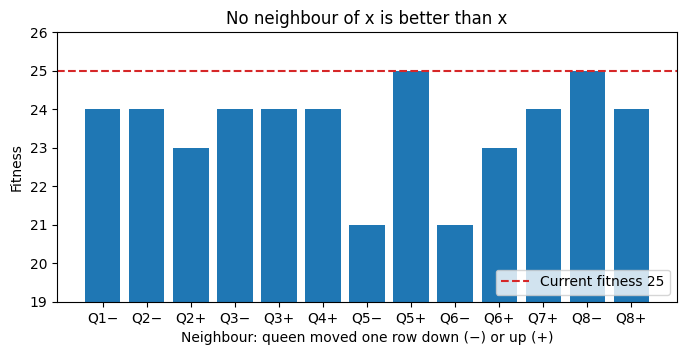

In [45]:
x = [7, 1, 2, 0, 5, 3, 0, 4]
labels, scores = [], []
for neighbour in get_neighbours(x):
    queen = next(i for i in range(n) if neighbour[i] != x[i])
    labels.append(f"Q{queen + 1}{'+' if neighbour[queen] > x[queen] else '−'}")
    scores.append(get_fitness(neighbour))

plt.figure(figsize=(8, 3.5))
plt.bar(labels, scores, color="tab:blue")
plt.axhline(get_fitness(x), color="tab:red", linestyle="--", label=f"Current fitness {get_fitness(x)}")
plt.ylim(min(scores) - 2, get_fitness(x) + 1)
plt.xlabel("Neighbour: queen moved one row down (−) or up (+)")
plt.ylabel("Fitness")
plt.title("No neighbour of x is better than x")
plt.legend(loc="lower right")

None of the neighbours of `x` has a better fitness value than `x` itself. Two of them (`Q5+` and `Q8−`) are equally good, forming a small _plateau_, but the hillclimber only accepts strictly better neighbours. It has nowhere to go, and is stuck.

## Fitness Landscapes

A **fitness landscape** consists of three things:

- the search space: every possible solution,
- the neighbourhood: which solutions are one step apart,
- the fitness of each solution, read as its *height*.

A **local optimum** is a solution with no better neighbour. A **global optimum** is a solution with the best fitness overall. A **plateau** is a region of neighbours with equal fitness.

A local search walks around this landscape, but it can only see the height of its current solution and its immediate neighbours. It cannot tell a local optimum from a global one.

A landscape is **not** a property of the problem alone: it also depends on the neighbourhood. With a different `get_neighbours`, the same solutions and fitness function form a different landscape, possibly with fewer local optima or none at all. Choosing the neighbourhood is a design decision, and often matters more than the choice of algorithm.

### A landscape we can actually look at

The n-queens landscape has one dimension per queen, far too many to draw. We can look at a two-dimensional **slice** through it instead: fix every queen but two, and vary the rows of those two across the whole board. The result is a grid of fitness values that we can plot, and it is a genuine piece of the landscape our algorithms search. We use a larger board here only because it makes a bigger picture.

In [46]:
import numpy as np

# Fix every queen but the first two, then vary those two across the whole board.
slice_n = 30
fixed_board = [random.randint(0, slice_n - 1) for _ in range(slice_n)]

def slice_fitness(point):
    row_a, row_b = point
    board = fixed_board[:]
    board[0], board[1] = row_a, row_b
    return get_fitness(board)      # exactly the n-queens fitness defined earlier

slice_grid = np.array([[slice_fitness((a, b)) for b in range(slice_n)]
                       for a in range(slice_n)])

print(f"Across this slice, fitness ranges from {slice_grid.min()} to {slice_grid.max()}")

Across this slice, fitness ranges from 400 to 410


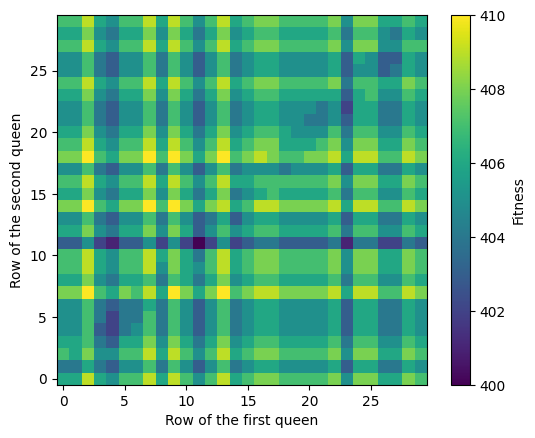

In [47]:
def plot_slice(colourbar=True):
    plt.imshow(slice_grid.T, origin="lower", cmap="viridis", interpolation="nearest")
    if colourbar:
        plt.colorbar(label="Fitness")
    plt.xlabel("Row of the first queen")
    plt.ylabel("Row of the second queen")


plot_slice()

Two things are worth noticing.

The dark bands running across the picture are the rows in which one of our two movable queens collides with a queen we left fixed. A whole line of the plot drops in fitness at once, regardless of what the other queen is doing. The fainter diagonal structure comes from the diagonal attacks. This is the constraint structure of the problem, made visible.

Between the bands the surface is **bumpy**. There is no single smooth hill leading to the best cell; instead there are a great many small peaks, and the brightest cell is only slightly brighter than a good number of its rivals. A hillclimber dropped anywhere on this picture will walk uphill until it reaches whichever small peak happens to be nearest, and then stop.

We can watch exactly that happen. Since each of our two queens can move up or down by one row, searching inside this slice uses the same neighbourhood we defined for n-queens, just restricted to two queens:

In [48]:
def slice_neighbours(point):
    row_a, row_b = point
    candidates = [(row_a + 1, row_b), (row_a - 1, row_b),
                  (row_a, row_b + 1), (row_a, row_b - 1)]
    return [(a, b) for a, b in candidates
            if 0 <= a < slice_n and 0 <= b < slice_n]

Rather than writing a separate loop for every algorithm, we separate *how a search moves* from *recording where it went*. `search_path` repeatedly asks a `choose_next` function for the next point and keeps the whole trail. Each algorithm in this chapter then only has to supply its own step rule.

In [49]:
def search_path(start, choose_next, steps):
    """Record the path a local search takes through the landscape."""
    current = start
    path = [current]
    for step in range(steps):
        current = choose_next(current, step)
        path.append(current)
    return path

The step rule for hillclimbing is the one we already know: look at all neighbours, and move to the best one if it is an improvement. Otherwise the search stays where it is -- once it is stuck, every further step returns the same point.

In [50]:
def hillclimb_step(current, step_number):
    """Move to the best neighbour, but only if it is an improvement."""
    best = max(slice_neighbours(current), key=slice_fitness)
    return best if slice_fitness(best) > slice_fitness(current) else current

To draw a trail, we connect consecutive points with a white line. Some of the later searches will *jump* rather than step (random restarts, for example), so `plot_path` breaks the line whenever two consecutive points are not neighbours, instead of drawing a misleading line straight across the landscape.

In [51]:
def plot_path(path, linewidth=1.4):
    """Draw a search path in white, breaking the line wherever the search jumped."""
    segment = [path[0]]
    for point in path[1:]:
        if abs(point[0] - segment[-1][0]) + abs(point[1] - segment[-1][1]) > 1:
            plt.plot(*zip(*segment), color="white", linewidth=linewidth)
            segment = []
        segment.append(point)
    plt.plot(*zip(*segment), color="white", linewidth=linewidth)

`show_path` puts the pieces together: it draws the slice, overlays the trail, marks where the search started and where it ended, and reports the best fitness the search saw and how much of the slice it visited.

In [52]:
def show_path(path, title, linewidth=1.4, mark_end=True):
    """Plot one search path on the slice and summarise what it visited."""
    plt.figure(figsize=(7, 6))
    plot_slice()
    plot_path(path, linewidth)
    plt.plot(*path[0], 'o', color="black", markersize=8, label="Start")
    if mark_end:
        plt.plot(*path[-1], 'X', color="white", markersize=12,
                 markeredgecolor="black", label="End")
    plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2,
               fontsize="small", frameon=False)
    plt.title(title)
    print(f"Best fitness visited: {max(map(slice_fitness, path))} "
          f"(best in this slice: {slice_grid.max()}); "
          f"distinct cells visited: {len(set(path))} of {slice_n * slice_n}")

Before we watch a single climb, let's ask the question for every starting point at once: from each cell of the slice, let the hillclimber run until it stops, and check whether it ended on the best fitness in the slice.

In [53]:
# Where does a hillclimber end up from each of the 900 cells?
cells = [(a, b) for a in range(slice_n) for b in range(slice_n)]
ends = {cell: search_path(cell, hillclimb_step, 100)[-1] for cell in cells}
stuck = [cell for cell in cells if slice_fitness(ends[cell]) < slice_grid.max()]
print(f"From {len(stuck)} of {len(cells)} cells, hillclimbing stops below the best fitness in the slice")

From 786 of 900 cells, hillclimbing stops below the best fitness in the slice


To see what this looks like, we pick one starting cell from which the hillclimber gets stuck, but only after a few steps, so that there is a visible trail. Every search on the slice in this chapter starts from this same point, so the pictures can be compared.

Best fitness visited: 409 (best in this slice: 410); distinct cells visited: 4 of 900


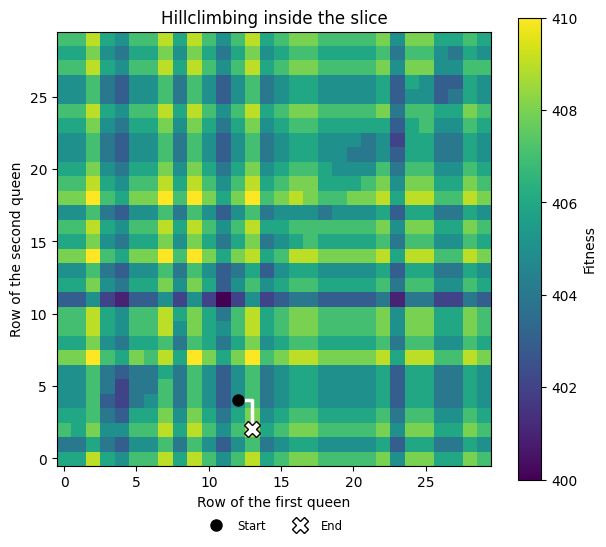

In [54]:
def random_cell():
    return (random.randrange(slice_n), random.randrange(slice_n))

def cells_visited(cell):
    return len(set(search_path(cell, hillclimb_step, 50)))

# Starting points from which hillclimbing takes a few steps, then gets stuck below the best fitness
good_examples = [cell for cell in stuck if cells_visited(cell) >= 4]
start = random.choice(good_examples)   # every search on the slice starts here, so the pictures can be compared

path_steps = 300   # step budget for every search we draw on the slice, here and in Week 2

show_path(search_path(start, hillclimb_step, path_steps),
          "Hillclimbing inside the slice", linewidth=2.5)

The hillclimber walks a short way uphill and then stops on a peak that is not the best one in the picture -- as it does from most starting cells, according to the count above. All of its neighbours are worse, so by its own rule it has finished -- and it has no way even to *tell* that it is standing on a minor peak rather than on the best solution available. Local optima and global optima look exactly the same to an algorithm that can only see its immediate neighbours.

This is the same failure as on the 8x8 board, but now we can watch it happen on a picture of the actual landscape. Week 2 is about ways to do something about it: restarting from somewhere else, remembering where we have already been, or allowing the search to move downhill on purpose.

## Random restarts and first ascent

A simple solution to this problem is to use _random restarts_: If the hillclimber is stuck in an optimum, we restart the search from a new random point. With some luck, the next attempt will climb a different optimum.

In [55]:
def hillclimbing_restart():
    evaluate = Evaluations(get_fitness, max_steps)
    current = get_random_solution()
    fitness = evaluate(current)
    while evaluate.remaining:
        candidate, candidate_fitness = current, fitness
        for neighbour in get_neighbours(current):
            if not evaluate.remaining:
                break
            score = evaluate(neighbour)
            if score > candidate_fitness:
                candidate, candidate_fitness = neighbour, score
        if candidate_fitness > fitness:
            current, fitness = candidate, candidate_fitness
        elif evaluate.remaining:
            current = get_random_solution()
            fitness = evaluate(current)
    return evaluate.result()

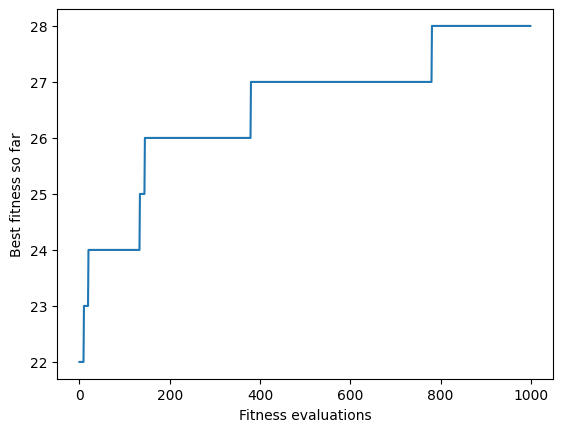

In [56]:
solution, history = hillclimbing_restart()
plot_history(history)

With random restarts, the hillclimber uses its whole budget instead of stopping at the first local optimum, and it may climb a better hill on a later attempt. It still doesn't always find the best solution, depending on what value you choose for `max_steps`; whether it beats random search is a question for repeated runs, which we will do below.

### Restarts on the slice

We can see what the restarts are actually doing by running the same idea on the two-dimensional slice from earlier, beginning at the same point our plain hillclimber started from.

Best fitness visited: 410 (best in this slice: 410); distinct cells visited: 225 of 900


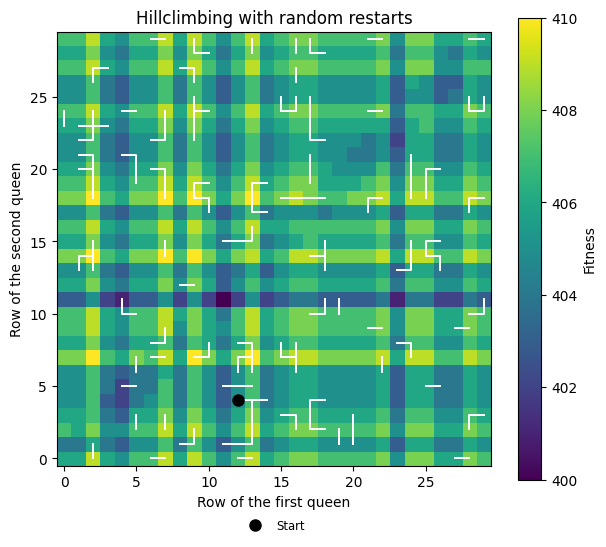

In [57]:
def restart_step(current, step_number):
    """Climb to the best neighbour; if nothing improves, jump somewhere new."""
    best = max(slice_neighbours(current), key=slice_fitness)
    if slice_fitness(best) > slice_fitness(current):
        return best
    return random_cell()


show_path(search_path(start, restart_step, path_steps),
          "Hillclimbing with random restarts", mark_end=False)

The single connected trail has become a scatter of short, disconnected climbs. Each one begins wherever the previous attempt gave up, races up the nearest slope, and stops -- and because the restart point is drawn uniformly at random, the next climb almost always begins nowhere near the last one.

That is the trade the restarts make. The search now covers far more of the landscape than the lone hillclimber did, so it is much less at the mercy of where it happened to begin. But it also discards everything it has learned every time it restarts: a restart is exactly as likely to land in a hopeless region as a promising one, and a climb that was heading somewhere good gets no more attention than one that was not.

The version we considered is called _steepest ascent_ hillclimbing, because it will always explore all neighbours, and then pick the best one. An alternative approach is _first ascent_, which will pick the first neighbour that has a better fitness value. We scan the neighbours in random order; with a fixed order, first ascent would always try to move the first queen before any other. Like the previous version, it restarts from a random solution when no neighbour improves.

In [58]:
def hillclimbing_first_ascent():
    evaluate = Evaluations(get_fitness, max_steps)
    current = get_random_solution()
    fitness = evaluate(current)
    while evaluate.remaining:
        improved = False
        neighbours = get_neighbours(current)
        random.shuffle(neighbours)   # a fixed scan order would favour the first queens
        for neighbour in neighbours:
            if not evaluate.remaining:
                break
            score = evaluate(neighbour)
            if score > fitness:
                current, fitness, improved = neighbour, score, True
                break
        if not improved and evaluate.remaining:
            current = get_random_solution()
            fitness = evaluate(current)
    return evaluate.result()

For some problems, a first-ascent strategy may be less likely to run into local optima, because it is not so "eager" to climb the hill. However, this depends on the problem at hand, and luck. 

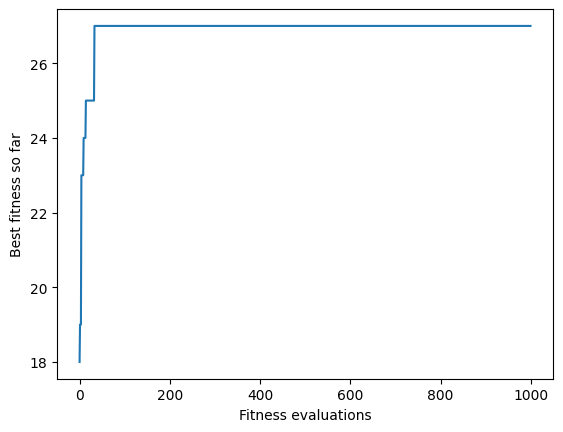

In [59]:
solution, history = hillclimbing_first_ascent()
plot_history(history)

For our n-queens problem, is steepest ascent or first ascent better? And is either of them better than random search? To find out, we can run all three algorithms and compare the results.

In [60]:
def plot_single_runs(searches):
    """Run each search once and plot its history."""
    for name, search in searches.items():
        plot_history(search()[1], label=name)
    plt.legend()

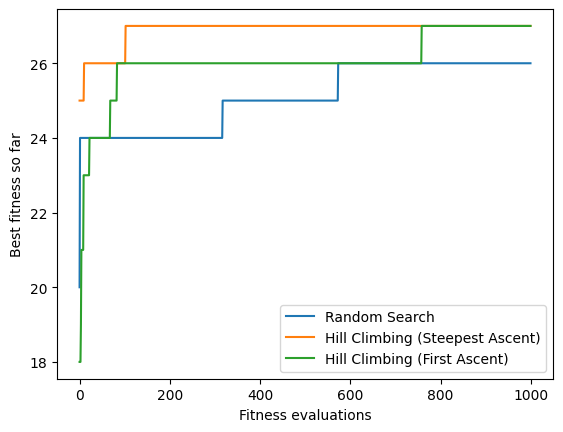

In [61]:
plot_single_runs({"Random Search": randomsearch,
                  "Hill Climbing (Steepest Ascent)": hillclimbing_restart,
                  "Hill Climbing (First Ascent)": hillclimbing_first_ascent})

A single stochastic run is not enough to establish an ordering between algorithms. Repeat the experiment and inspect the spread of outcomes.

The implementations already count actual objective calls. Steepest ascent spends several evaluations on each move; first ascent stops a scan after an improvement. Both must stop at the same evaluation cap, including initialization. This makes different amounts of search work visible on the horizontal axis.

Fitness evaluations and elapsed time answer different questions. Equal evaluation budgets isolate how efficiently an algorithm uses objective information. Equal time budgets include overhead and differences in the cost of evaluating candidates.

Here we use objective-call budgets, with one history entry per call. The compiler table is a frozen lookup: it removes compilation and measurement noise from the search demonstration. A live compiler experiment would also need repeated measurements and compiler, hardware and source provenance.

There probably isn't a clear winner yet. We will first introduce two algorithms that cope better with local optima, and then turn to the question of how to compare algorithms properly.

## Tabu Search

In tabu search, a tabu list prevents re-exploration of already visited parts of search space, but therefore the search is allowed to make moves in the search space that lead to worse fitness (whereas hillclimbing only allows moves that improve fitness).

The tabu list is often implemented as a circular buffer: each solution the search *moves to* is appended to the buffer, and solutions are removed from the front once they have been in the buffer for a certain number of steps. The solutions in the buffer are the ones the search is forbidden ("tabu") to revisit. Let's introduce a parameter to denote the size of our buffer.

In [62]:
tabu_size = 50

The algorithm itself is very similar to hillclimbing, except for the following changes:
- Only neighbours that are not in the tabu list are considered
- The search moves to the best neighbour, even if that neighbour has worse fitness
- The neighbour that was moved to is appended to the tabu list at each step, and the oldest entry is dropped once the list exceeds `tabu_size`
- If every neighbour is tabu, the search restarts from a random solution

Many tabu search variants store *moves* or solution attributes rather than whole solutions, and add an _aspiration criterion_: a tabu move is allowed anyway if it would produce a new best solution. Our list stores complete solutions that have already been visited, so a tabu neighbour can never be a new best, and aspiration is not needed here.

In [63]:
def tabusearch():
    evaluate = Evaluations(get_fitness, max_steps)
    current = get_random_solution()
    evaluate(current)
    tabu = [current]
    while evaluate.remaining:
        candidate, candidate_fitness = None, -math.inf
        for neighbour in get_neighbours(current):
            if not evaluate.remaining:
                break
            if neighbour in tabu:
                continue
            score = evaluate(neighbour)
            if score > candidate_fitness:
                candidate, candidate_fitness = neighbour, score
        if candidate is None:
            if not evaluate.remaining:
                break
            current = get_random_solution()
            evaluate(current)
            tabu = [current]
        else:
            current = candidate
            tabu = (tabu + [current])[-tabu_size:]
    return evaluate.result()

In [64]:
max_steps = 5000

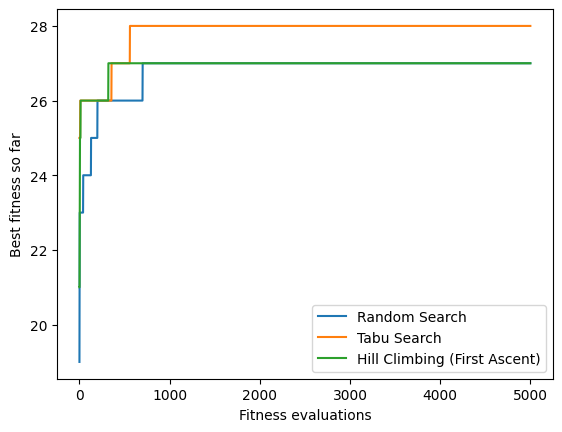

In [65]:
plot_single_runs({"Random Search": randomsearch,
                  "Tabu Search": tabusearch,
                  "Hill Climbing (First Ascent)": hillclimbing_first_ascent})

### Tabu search on the slice

The tabu list makes for a very different picture. Starting from the same point on the same slice as before, the search is forbidden from returning to the cells it has recently occupied, which forces it to keep moving even when every move available makes things worse.

Best fitness visited: 410 (best in this slice: 410); distinct cells visited: 192 of 900


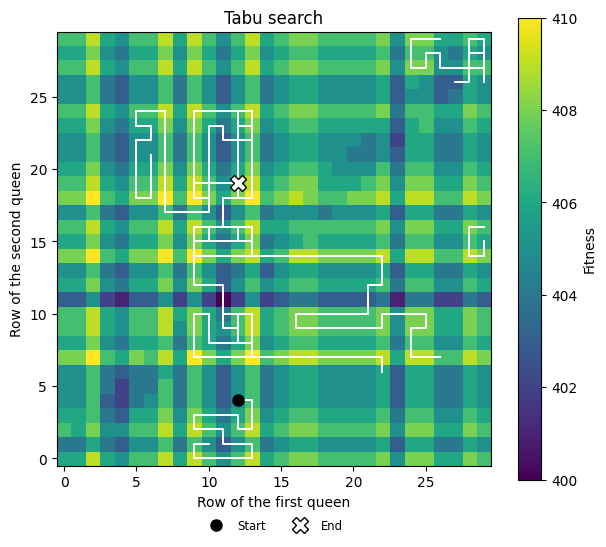

In [66]:
def tabu_step(size):
    """Move to the best neighbour that is not tabu, whether or not it is an improvement."""
    tabu = []

    def step(current, step_number):
        tabu.append(current)
        if len(tabu) > size:
            tabu.pop(0)

        candidates = [p for p in slice_neighbours(current) if p not in tabu]
        if not candidates:
            # Every neighbour is tabu, so restart -- exactly as `tabusearch` does
            restarted = random_cell()
            tabu.clear()
            tabu.append(restarted)
            return restarted
        return max(candidates, key=slice_fitness)

    return step


show_path(search_path(start, tabu_step(tabu_size), path_steps), "Tabu search")

Unlike the restarts, this is not a scatter of brief attempts. The search works its way steadily around a region and fills it in. The characteristic boxy shape comes from the tabu list itself: the search cannot retrace its steps, so it loops around them instead.

You will usually see several such regions rather than one. That happens when the list eventually forbids *every* neighbour of the current cell -- the search is walled in, and `tabusearch` responds by restarting, exactly as our implementation does.

So the contrast with the previous picture is not "one trail versus many", but how the effort is spent. The restarting hillclimber made a few hundred brief scrambles scattered everywhere, learning nothing from one to the next. Tabu search makes a handful of thoroughly worked-over patches. Which of those is the better use of a fixed budget depends on whether good solutions are clustered together or scattered about -- something we generally do not know in advance.

### The tabu list size

The behaviour we just saw depends entirely on `tabu_size`, which we set to 50 without any particular justification. Since the list is the only thing pushing the search onwards, it is worth seeing what different sizes actually do.

To put several sizes side by side, we need one more helper. `compare_paths` draws one panel per variant, all starting from the same point. Each variant is given as a function that *builds* a fresh step rule, so that every panel starts with its own empty tabu list.

In [67]:
def compare_paths(variants, steps, title):
    """One panel per variant, every one starting from the same point.

    `variants` maps a label to a function that builds a fresh move chooser,
    so that each panel starts with its own clean state.
    """
    plt.figure(figsize=(4.4 * len(variants), 4.6))
    for position, (label, make_chooser) in enumerate(variants.items(), start=1):
        plt.subplot(1, len(variants), position)
        path = search_path(start, make_chooser(), steps)
        plot_slice(colourbar=False)
        plot_path(path, linewidth=1.1)
        plt.plot(*start, 'o', color="black", markersize=7)
        plt.title(f"{label}\n{len(set(path))} cells, "
                  f"best {max(map(slice_fitness, path))}")
        if position > 1:
            plt.ylabel("")
    plt.suptitle(title)
    plt.tight_layout()

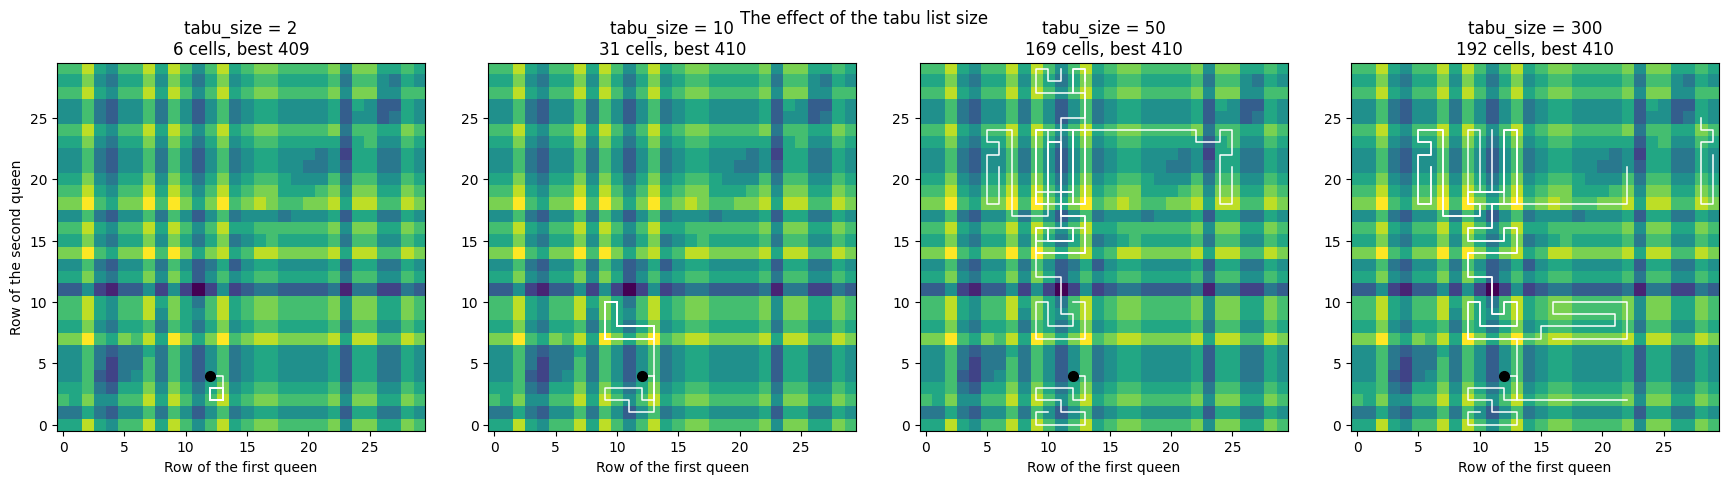

In [68]:
compare_paths({f"tabu_size = {size}": (lambda s=size: tabu_step(s))
               for size in [2, 10, 50, 300]},
              path_steps,
              "The effect of the tabu list size")

The size of the list controls how far the search ranges, and the effect is large.

With `tabu_size = 2` the search barely goes anywhere. Only the last two cells are forbidden, which is not enough to stop it walking back the way it came a few steps later, so it winds up in a tight knot around a single peak. This is very nearly the plain hillclimber, just with a twitch.

As the list gets longer, more and more of the ground around the search is closed off, and the trail is pushed steadily further afield.

Beyond a certain point the returns diminish, and for an interesting reason. A long list eventually forbids *every* neighbour of the current cell, at which point the search is walled in and has to restart -- so the largest setting starts to look more like the random restarts we saw earlier, and less like the patient sweep that makes tabu search distinctive. Longer still changes nothing at all, because the list never gets a chance to fill up before a restart clears it.

So there is a sensible middle range rather than a "bigger is better" rule, and where that range falls depends on the problem, the neighbourhood, and the budget. We picked 50 by guesswork.

## Simulated Annealing

The last local search algorithm we will consider is simulated annealing, which is another variant of hillclimbing with a twist in order to escape local optima. The algorithm simulates physical processes from metallurgy, where the atoms in heated metal undergo disordered movements of large amplitude, while cooling the metal down progressively reduces movement and stabilises atoms around fixed positions in a regular crystal structure with minimal energy.

In order to simulate these effects, we will require some helper maths functions.

In [69]:
import math

The central aspect of simulated annealing is that the local search sometimes accepts movements to neighbours with worse fitness values, and does so more readily when the temperature is high (just like atoms move more freely in heated metal). To calculate the acceptance probability, we need to compare the current individual of the search and a neighbour. If the neighbour is at least as good, the probability of accepting it is `1`. If it is worse by $\Delta = f(\text{current}) - f(\text{neighbour}) > 0$, the probability is $e^{-\Delta / T}$ (the _Metropolis criterion_): small losses are accepted often, large losses rarely, and both become rarer as the temperature $T$ falls.

In [70]:
def acceptance_probability(fitness, new_fitness, temperature):
    if new_fitness > fitness:
        return 1
    else:
        p = math.exp( (new_fitness - fitness) / temperature)
        return p

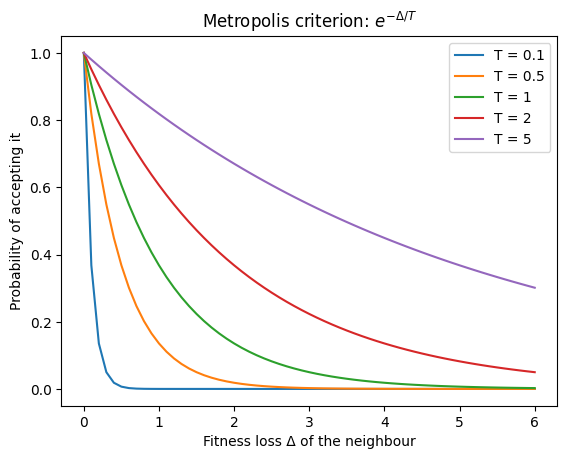

In [71]:
losses = np.linspace(0, 6, 61)
for T in [0.1, 0.5, 1, 2, 5]:
    plt.plot(losses, [acceptance_probability(0, -loss, T) for loss in losses], label=f"T = {T}")
plt.xlabel("Fitness loss Δ of the neighbour")
plt.ylabel("Probability of accepting it")
plt.title("Metropolis criterion: $e^{-Δ/T}$")
plt.legend()

The temperature is varied along the search, starting at a high value, and gradually cooling down. It is possible to use different cooling schedules; we will use a simple schedule where the temperature is calculated based on the fraction of the overall search budget (i.e., number of steps in the search) used.

In [72]:
def temperature(fraction):
    return max(0.01, min(1, 1 - fraction))

Unlike hillclimbing and tabu search, in each step we only consider one random neighbour. The acceptance probability then decides whether the search moves to this individual, or remains at the current position.

In [73]:
def simulatedannealing(schedule=None, trace=None):
    evaluate = Evaluations(get_fitness, max_steps)
    current = get_random_solution()
    fitness = evaluate(current)
    schedule = schedule or temperature
    if trace is not None:
        trace.append((fitness, evaluate.best_fitness))
        
    while evaluate.remaining:
        T = schedule(len(evaluate.history) / max_steps)
        candidate = random.choice(get_neighbours(current))
        score = evaluate(candidate)
        if acceptance_probability(fitness, score, T) > random.random():
            current, fitness = candidate, score
        if trace is not None:
            trace.append((fitness, evaluate.best_fitness))
    return evaluate.result()

In order to evaluate simulated annealing, let's first have a look at an individual run of the algorithm compared to individual runs of other algorithms.

### Current fitness versus best so far

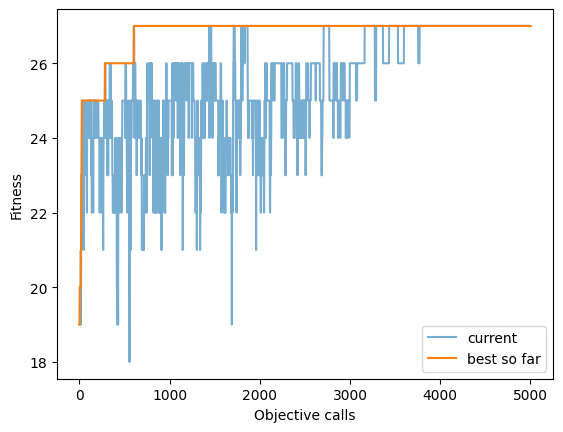

In [74]:
move_trace = []
_, _ = simulatedannealing(trace=move_trace)
current_scores, best_scores = zip(*move_trace)
plt.plot(range(1, len(move_trace)+1), current_scores, alpha=0.6, label="current")
plt.plot(range(1, len(move_trace)+1), best_scores, label="best so far")
plt.xlabel("Objective calls")
plt.ylabel("Fitness")
plt.legend()

The current score can fall after an accepted worsening move; the best-so-far score never does. In the optimisation literature, the best solution found so far is often called the *incumbent*. Note that the best so far may also be a proposal that was evaluated but then rejected: `Evaluations` records every candidate it scores, whether or not the search moves there. These are different records of a run, so label the one you plot.

In [75]:
max_steps = 5000

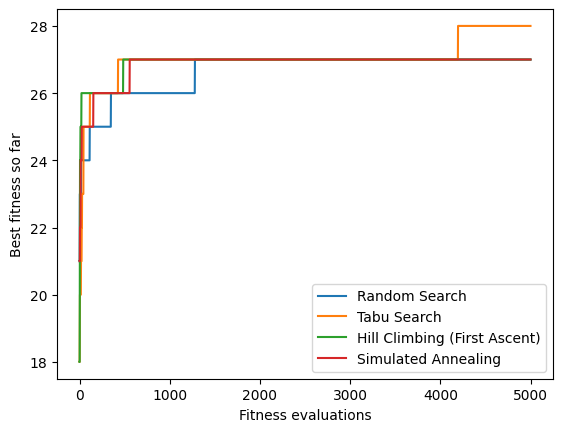

In [76]:
plot_single_runs({"Random Search": randomsearch,
                  "Tabu Search": tabusearch,
                  "Hill Climbing (First Ascent)": hillclimbing_first_ascent,
                  "Simulated Annealing": simulatedannealing})

### Simulated annealing on the slice

We use the same slice and starting point as for restarts and tabu search. Simulated annealing evaluates only one neighbour per step, whereas hillclimbing and tabu search evaluate all four, so we give it four times as many steps.

Best fitness visited: 409 (best in this slice: 410); distinct cells visited: 62 of 900


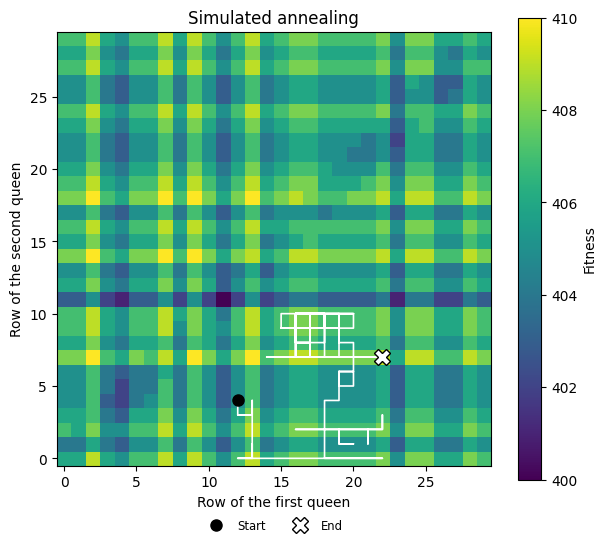

In [77]:
def anneal_step(budget, schedule=temperature):
    """A move chooser for simulated annealing, using the given cooling schedule."""
    def step(current, step_number):
        T = schedule(step_number / float(budget))
        neighbour = random.choice(slice_neighbours(current))
        if acceptance_probability(slice_fitness(current),
                                  slice_fitness(neighbour),
                                  T) > random.random():
            return neighbour
        return current
    return step


anneal_steps = 4 * path_steps
show_path(search_path(start, anneal_step(anneal_steps), anneal_steps),
          "Simulated annealing", linewidth=1.2)

While the temperature is high, the search often moves downhill and wanders across the slice. As it cools, downhill moves become rarer and the search settles on a peak.

### The cooling schedule

What happens if we cool differently? The temperature divides a difference in fitness, so what counts as "hot" depends on the scale of the fitness values: on this slice, neighbouring cells usually differ by one or two points.

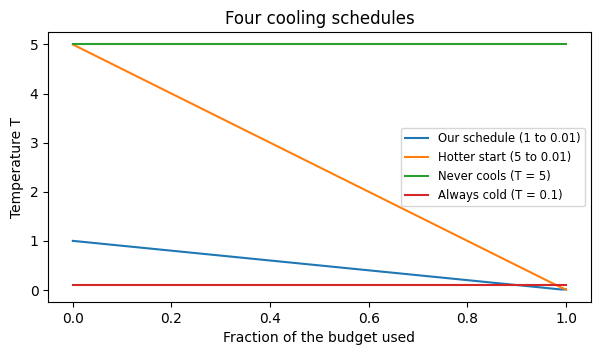

In [78]:
hotter = lambda fraction: max(0.01, 5 * (1 - fraction))
schedules = {
    "Our schedule (1 to 0.01)":  temperature,
    "Hotter start (5 to 0.01)":  hotter,
    "Never cools (T = 5)":       lambda fraction: 5.0,
    "Always cold (T = 0.1)":     lambda fraction: 0.1,
}

fractions = np.linspace(0, 1, 101)
plt.figure(figsize=(7, 3.5))
for name, schedule in schedules.items():
    plt.plot(fractions, [schedule(f) for f in fractions], label=name)
plt.xlabel("Fraction of the budget used")
plt.ylabel("Temperature T")
plt.title("Four cooling schedules")
plt.legend(fontsize="small")

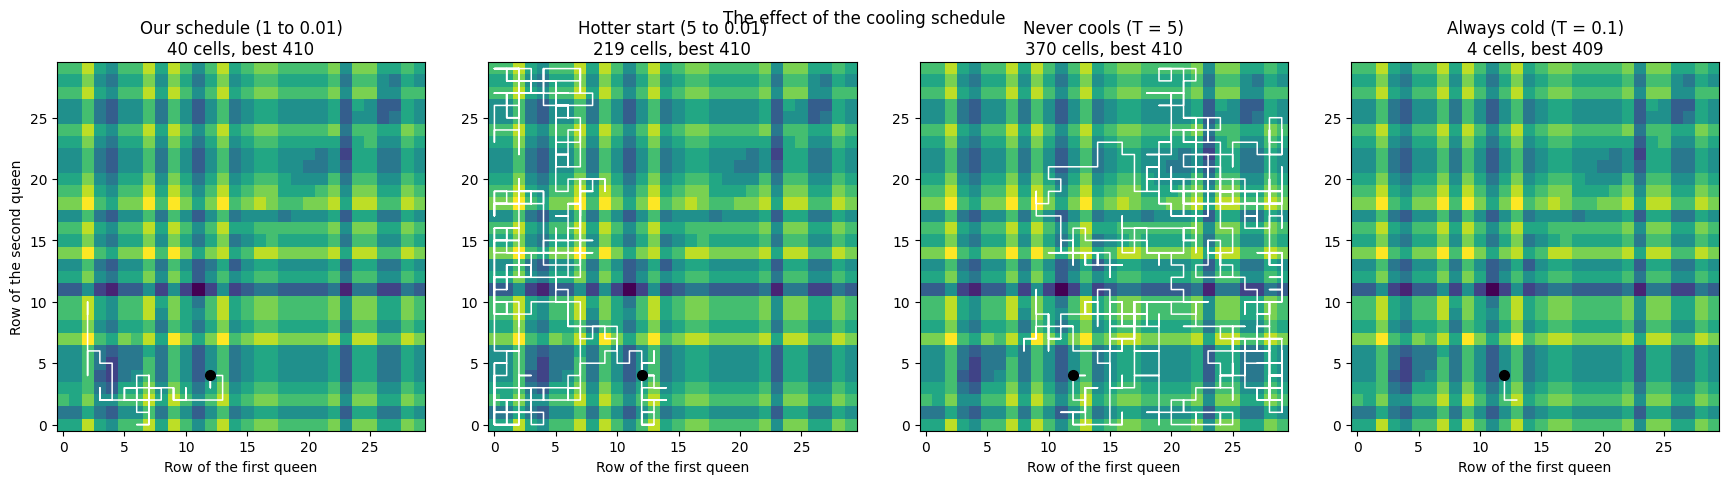

In [79]:
compare_paths({name: (lambda s=schedule: anneal_step(anneal_steps, s))
               for name, schedule in schedules.items()},
              anneal_steps,
              "The effect of the cooling schedule")

If the temperature is always low, worse moves are almost never accepted and simulated annealing behaves like hillclimbing. If it never cools, almost every move is accepted and the search behaves like a random walk. Our schedule and the hotter start both explore first and then settle, with the hotter start covering more ground. Whether that makes it better on the real problem is something we will check in Part 2.

Restarts, tabu search and simulated annealing all address the same problem: hillclimbing stops at the first local optimum it reaches. Restarts begin again somewhere else, tabu search avoids going back, and simulated annealing accepts worse moves, mostly early on. Keep in mind that on a slice of only 900 solutions, searches that sample widely look good -- the pictures show how the algorithms behave, not which one is better.

In Part 2 we will compare these algorithms properly, and look at ways to measure fitness landscapes.